### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there 'right away' or 'later before the coupon expires' are labeled as 'Y = 1' and answers 'no, I do not want the coupon' are labeled as 'Y = 0'.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - \$50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.

### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \$12500, \$12500 - \$24999, \$25000 - \$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \$20 per person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)

3. Coupon attributes
    - time before it expires: 2 hours or one day

**Imports**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Problems

Use the prompts below to get started with your data analysis.

1. Read in the `coupons.csv` file.

In [2]:
data = pd.read_csv('data/coupons.csv')
print(f"The dataset has {data.shape[0]} rows and {data.shape[1]} columns.")
data.head()

The dataset has 12684 rows and 26 columns.


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [3]:
# Quick overview of columns, types, and how many non-null values each has
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

In [4]:
# Count missing values per column, then show only the columns that have some
missing = data.isna().sum()
missing[missing > 0]

car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
dtype: int64

A few things jump out:

- `car` is almost entirely empty, around 99% missing, so there's nothing worth keeping there.
- Five of the "how often do you go" columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) have small gaps, roughly 1-2% of rows each.
- Worth flagging too: `passanger` is misspelled (it should be *passenger*). I've left the name untouched so the code matches the file.

3. Decide what to do about your missing data -- drop, replace, other...

I'm dropping `car` outright, since a column that's 99% empty can't support any real conclusion. The visit-frequency columns are a different case: they're categorical and barely missing anything, so rather than throwing out rows up front I'll leave the gaps in and let them drop out on their own whenever a question happens to filter on that column. That keeps thousands of otherwise complete rows in play.

In [5]:
# Remove the near-empty 'car' column
data = data.drop(columns='car')
# Confirm only the low-rate frequency columns still have missing values
still_missing = data.isna().sum()
still_missing[still_missing > 0]

Bar                     107
CoffeeHouse             217
CarryAway               151
RestaurantLessThan20    130
Restaurant20To50        189
dtype: int64

4. What proportion of the total observations chose to accept the coupon?

In [6]:
accept_rate = data['Y'].mean()
print(f"Overall acceptance rate: {accept_rate:.1%}")
# Raw counts of each outcome for context
data['Y'].value_counts()

Overall acceptance rate: 56.8%


Y
1    7210
0    5474
Name: count, dtype: int64

`Y` is coded 1 for accepted and 0 for rejected, and with only those two values the mean of the column is all I need: averaging a 0/1 variable just returns the share of 1s, which is exactly the acceptance rate. The `value_counts()` above shows the two outcomes it is averaging over. Here it comes out to about 56.8%, so a little more than half of all coupons were accepted.

5. Use a bar plot to visualize the `coupon` column.

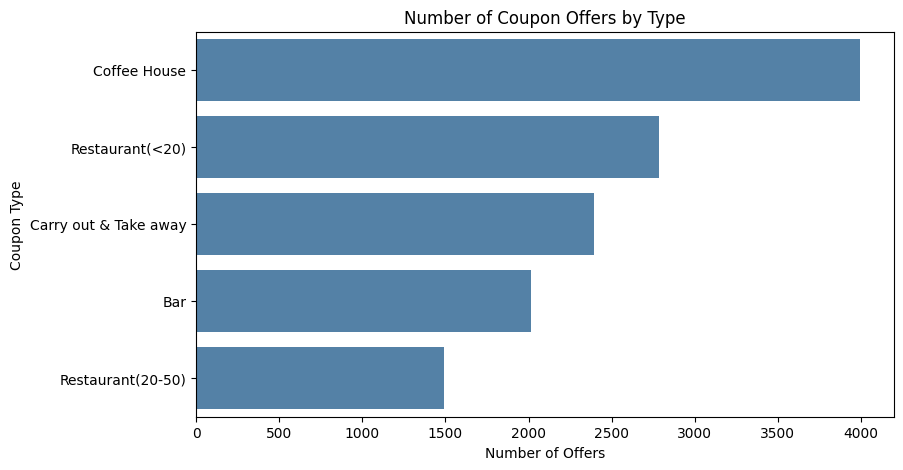

In [7]:
# Count offers per coupon type (value_counts sorts most-common first)
coupon_counts = data['coupon'].value_counts()
plt.figure(figsize=(9, 5))
sns.barplot(x=coupon_counts.values, y=coupon_counts.index, color='steelblue')
plt.title('Number of Coupon Offers by Type')
plt.xlabel('Number of Offers')
plt.ylabel('Coupon Type')
plt.show()

Coffee house coupons were offered the most, close to 4,000 of them, followed by the cheaper restaurants and carry-out. The pricier restaurant coupons came up least often.

6. Use a histogram to visualize the `temperature` column.

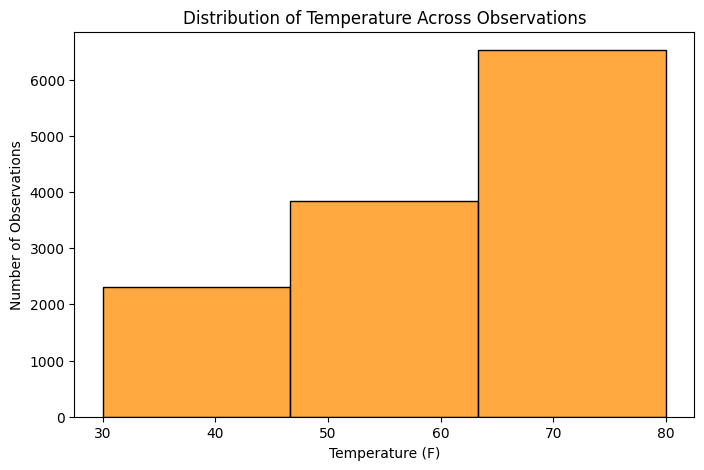

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='temperature', bins=3, color='darkorange')
plt.title('Distribution of Temperature Across Observations')
plt.xlabel('Temperature (F)')
plt.ylabel('Number of Observations')
plt.show()

Most observations fall at the warmest temperature, 80 F, with fewer at 55 and 30.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.

1. Create a new `DataFrame` that contains just the bar coupons.

In [9]:
bar = data[data['coupon'] == 'Bar']
print(f"Bar coupon offers: {len(bar)}")
bar.head()

Bar coupon offers: 2017


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1


2. What proportion of bar coupons were accepted?

In [10]:
bar_accept = bar['Y'].mean()
print(f"Bar coupon acceptance rate: {bar_accept:.1%}")

Bar coupon acceptance rate: 41.0%


Only 41% of bar coupons were accepted, well under the 56.8% across all coupon types. These are a harder sell.

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.

3 or fewer bar visits/month: 37.1% accept
More than 3 bar visits/month: 76.9% accept


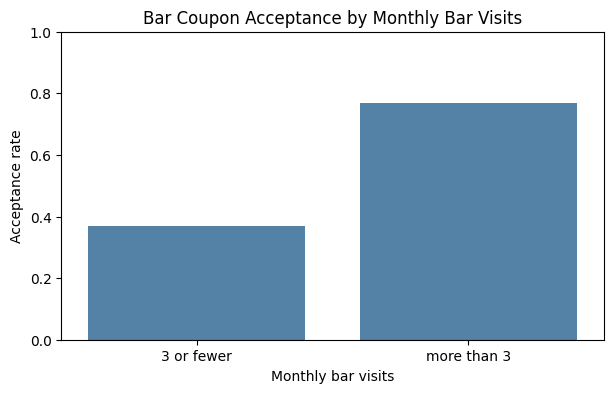

In [11]:
few_visits = ['never', 'less1', '1~3']     # 3 or fewer times a month
many_visits = ['4~8', 'gt8']                # more than 3 times a month
rate_few = bar[bar['Bar'].isin(few_visits)]['Y'].mean()
rate_many = bar[bar['Bar'].isin(many_visits)]['Y'].mean()
print(f"3 or fewer bar visits/month: {rate_few:.1%} accept")
print(f"More than 3 bar visits/month: {rate_many:.1%} accept")
# Put the two rates in a small DataFrame so Seaborn can plot them
q3 = pd.DataFrame({'bar_visits': ['3 or fewer', 'more than 3'],
                   'acceptance_rate': [rate_few, rate_many]})
plt.figure(figsize=(7, 4))
sns.barplot(data=q3, x='bar_visits', y='acceptance_rate', color='steelblue')
plt.title('Bar Coupon Acceptance by Monthly Bar Visits')
plt.xlabel('Monthly bar visits')
plt.ylabel('Acceptance rate')
plt.ylim(0, 1)
plt.show()

The gap is stark. People who hit a bar more than three times a month accept 77% of the time, against 37% for everyone who goes less often. These are two separate groups, so each figure is the acceptance rate *within* that group, not two shares of one total; that's why they needn't add up to 100%. The same reading applies to every group-versus-group comparison below. How much someone already goes out clearly matters here.

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?

Bar >1/month & over 25: 69.5% accept
Everyone else:          33.5% accept


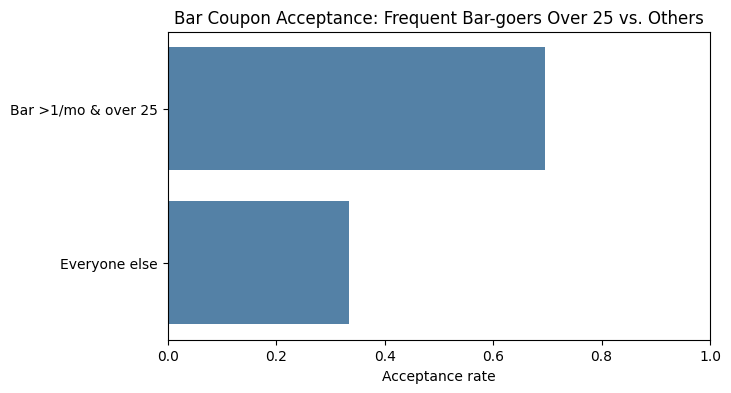

In [12]:
more_than_once = ['1~3', '4~8', 'gt8']     # more than once a month
age_25_or_under = ['below21', '21']        # 25 and under
# Mask: goes to a bar more than once/month AND is over 25
mask_q4 = bar['Bar'].isin(more_than_once) & ~bar['age'].isin(age_25_or_under)
rate_group = bar[mask_q4]['Y'].mean()
rate_others = bar[~mask_q4]['Y'].mean()
print(f"Bar >1/month & over 25: {rate_group:.1%} accept")
print(f"Everyone else:          {rate_others:.1%} accept")
q4 = pd.DataFrame({'group': ['Bar >1/mo & over 25', 'Everyone else'],
                   'acceptance_rate': [rate_group, rate_others]})
plt.figure(figsize=(7, 4))
sns.barplot(data=q4, x='acceptance_rate', y='group', color='steelblue')
plt.title('Bar Coupon Acceptance: Frequent Bar-goers Over 25 vs. Others')
plt.xlabel('Acceptance rate')
plt.ylabel('')
plt.xlim(0, 1)
plt.show()

Yes, a clear difference: that group accepts 70% of the time versus 34% for everyone else, a wide gap.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.

Target group:  71.3% accept
Everyone else: 29.6% accept


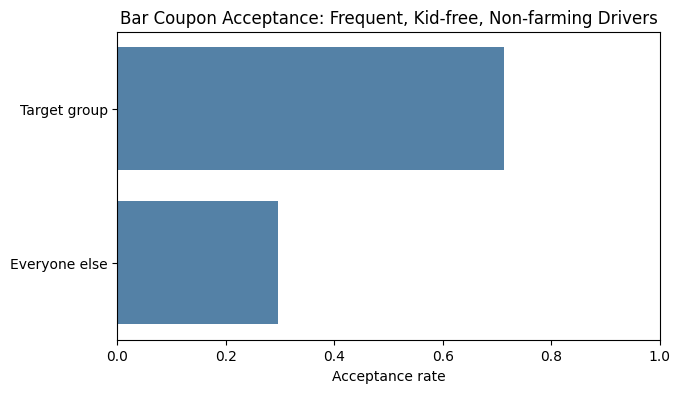

In [13]:
mask_q5 = (
    bar['Bar'].isin(more_than_once)
    & (bar['passanger'] != 'Kid(s)')
    & (bar['occupation'] != 'Farming Fishing & Forestry')
)
rate_group = bar[mask_q5]['Y'].mean()
rate_others = bar[~mask_q5]['Y'].mean()
print(f"Target group:  {rate_group:.1%} accept")
print(f"Everyone else: {rate_others:.1%} accept")
q5 = pd.DataFrame({'group': ['Target group', 'Everyone else'],
                   'acceptance_rate': [rate_group, rate_others]})
plt.figure(figsize=(7, 4))
sns.barplot(data=q5, x='acceptance_rate', y='group', color='steelblue')
plt.title('Bar Coupon Acceptance: Frequent, Kid-free, Non-farming Drivers')
plt.xlabel('Acceptance rate')
plt.ylabel('')
plt.xlim(0, 1)
plt.show()

This group lands at 71% against 30%. As with the last cut, the frequent-visitor piece of the condition is doing most of the work.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.

C1 (bars >1/mo, no kid, not widowed):   71.3% accept
C2 (bars >1/mo, under 30):              72.2% accept
C3 (cheap rest. >4/mo, income <50K):    45.3% accept

C1, C2 and C3 Combined:                 58.9% accept
Everyone else:                          29.8% accept


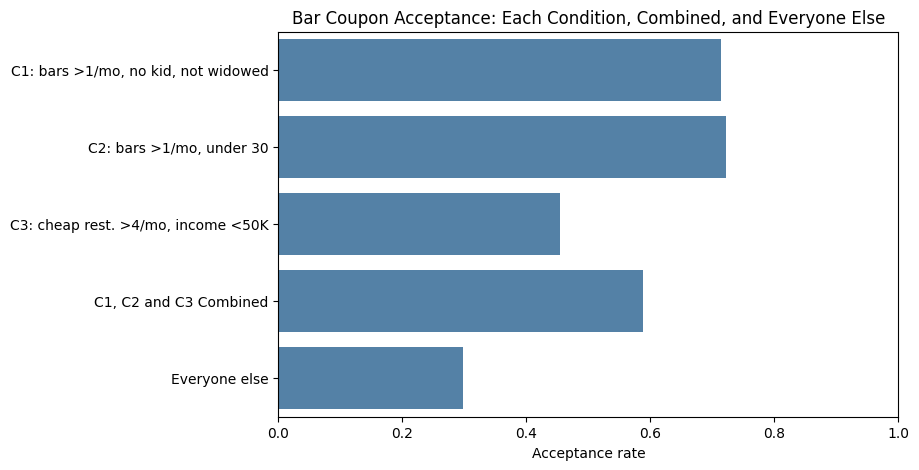

In [14]:
# NOTE: this prompt is ambiguously worded. "Compare the acceptance rates between
# those drivers who [A] OR [B] OR [C]" never says what to compare against. Because
# the three bullets are joined by OR, I read them as ONE combined group (a driver
# qualifies if ANY condition holds) and compare that group to everyone else. For
# transparency I also report each condition's acceptance rate on its own.
under_30 = ['below21', '21', '26']
cheap_often = ['4~8', 'gt8']               # cheap restaurant >4 times/month
low_income = ['Less than $12500', '$12500 - $24999',
              '$25000 - $37499', '$37500 - $49999']

cond1 = (bar['Bar'].isin(more_than_once)
         & (bar['passanger'] != 'Kid(s)')
         & (bar['maritalStatus'] != 'Widowed'))
cond2 = bar['Bar'].isin(more_than_once) & bar['age'].isin(under_30)
cond3 = bar['RestaurantLessThan20'].isin(cheap_often) & bar['income'].isin(low_income)

# Each condition on its own
rate1 = bar[cond1]['Y'].mean()
rate2 = bar[cond2]['Y'].mean()
rate3 = bar[cond3]['Y'].mean()
print(f"C1 (bars >1/mo, no kid, not widowed):   {rate1:.1%} accept")
print(f"C2 (bars >1/mo, under 30):              {rate2:.1%} accept")
print(f"C3 (cheap rest. >4/mo, income <50K):    {rate3:.1%} accept")

# The three combined with OR, versus everyone else
mask_q6 = cond1 | cond2 | cond3
rate_group = bar[mask_q6]['Y'].mean()
rate_others = bar[~mask_q6]['Y'].mean()
print(f"\nC1, C2 and C3 Combined:                 {rate_group:.1%} accept")
print(f"Everyone else:                          {rate_others:.1%} accept")

q6 = pd.DataFrame({
    'group': ['C1: bars >1/mo, no kid, not widowed',
              'C2: bars >1/mo, under 30',
              'C3: cheap rest. >4/mo, income <50K',
              'C1, C2 and C3 Combined',
              'Everyone else'],
    'acceptance_rate': [rate1, rate2, rate3, rate_group, rate_others]
})
plt.figure(figsize=(8, 5))
sns.barplot(data=q6, x='acceptance_rate', y='group', color='steelblue')
plt.title('Bar Coupon Acceptance: Each Condition, Combined, and Everyone Else')
plt.xlabel('Acceptance rate')
plt.ylabel('')
plt.xlim(0, 1)
plt.show()

Because the three bullets are joined by OR, I treat them as a single group: a driver counts if any one condition holds. Taken together that group accepts 58.9% of the time against 29.8% for everyone else. Looking at the conditions on their own, the two bar-going ones land around 71-72% while the cheap-restaurant / lower-income one is more modest at 45%, still above the ~30% baseline for everyone else. The prompt never states the comparison group, so this combined-versus-rest reading is the interpretation I went with.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Pulling it together, the people who accept bar coupons are mostly the people who already spend time in bars. Frequent bar-goers accept at roughly double the rate of everyone else, and the effect sharpens a little when they're over 25 and don't have a kid along. These coupons work best as a nudge to existing regulars, not as a way to win over people who rarely go out.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.

I'm taking the **coffee house** coupons, the most frequently offered group, so what drives acceptance there has the widest reach. The question is the same as for the bar coupons: what separates the drivers who take a coffee house coupon from the ones who pass?

For the plots below I pass the filtered data straight into `sns.barplot(x=category, y='Y')`. Seaborn averages `Y` within each category, which is exactly the acceptance rate, and the thin line on each bar is a 95% confidence interval, so I get both the rate and a feel for how firm it is.

In [15]:
coffee = data[data['coupon'] == 'Coffee House']
print(f"Coffee House offers: {len(coffee)}")
print(f"Coffee House acceptance rate: {coffee['Y'].mean():.1%}")

Coffee House offers: 3996
Coffee House acceptance rate: 49.9%


Coffee house acceptance sits right around 50% overall, close enough to a toss-up that the surrounding context has room to swing it either way. I looked at four things in particular: time of day, who else is in the car, how often the person already goes for coffee, and how long the coupon lasts.

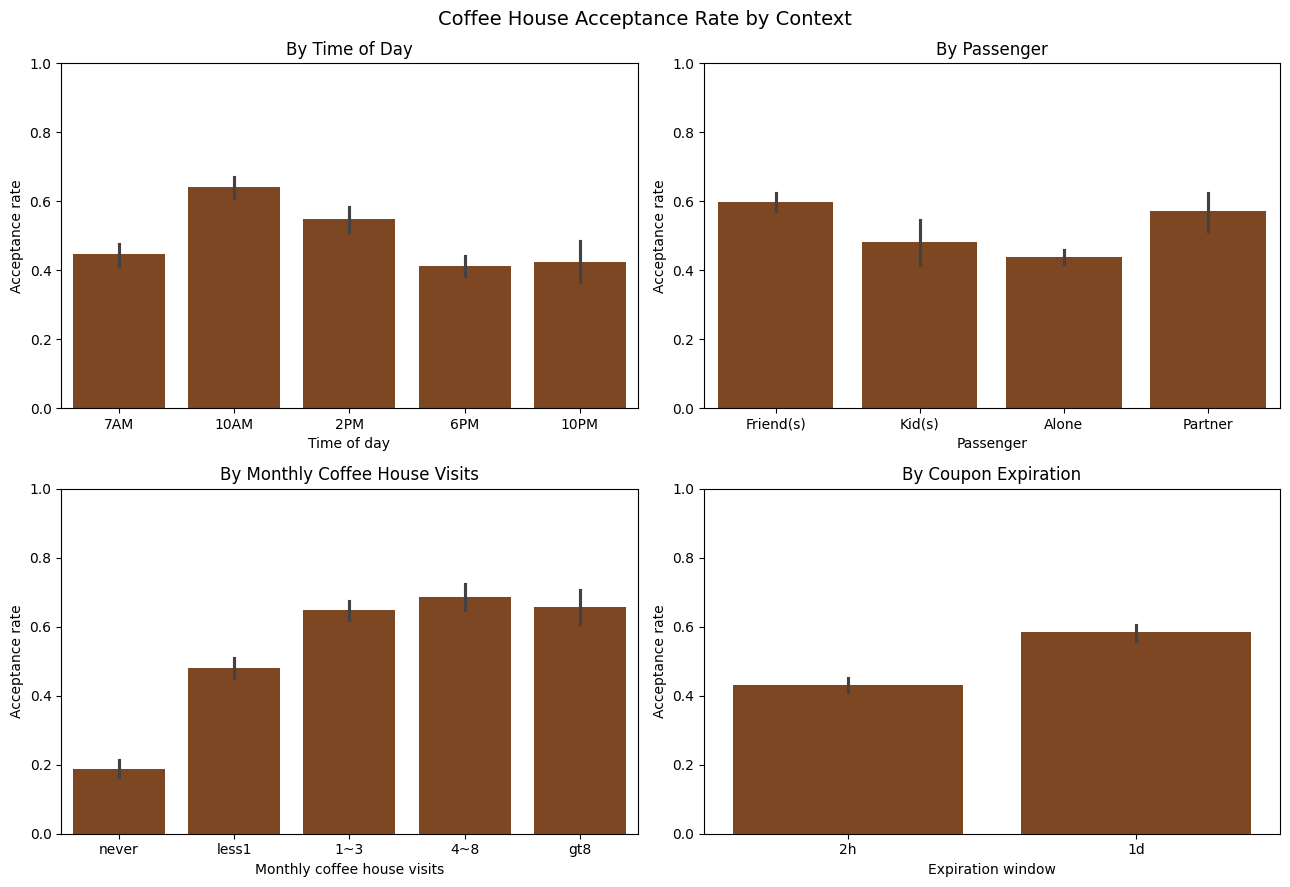

In [16]:
# All four coffee-house context factors in one 2x2 figure for easy comparison.
# Each panel is an sns.barplot of the acceptance rate (mean of Y) for that factor.
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']
visit_order = ['never', 'less1', '1~3', '4~8', 'gt8']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Coffee House Acceptance Rate by Context', fontsize=14)

sns.barplot(data=coffee, x='time', y='Y', order=time_order,
            color='saddlebrown', ax=axes[0, 0])
axes[0, 0].set_title('By Time of Day')
axes[0, 0].set_xlabel('Time of day')
axes[0, 0].set_ylabel('Acceptance rate')
axes[0, 0].set_ylim(0, 1)

sns.barplot(data=coffee, x='passanger', y='Y',
            color='saddlebrown', ax=axes[0, 1])
axes[0, 1].set_title('By Passenger')
axes[0, 1].set_xlabel('Passenger')
axes[0, 1].set_ylabel('Acceptance rate')
axes[0, 1].set_ylim(0, 1)

sns.barplot(data=coffee, x='CoffeeHouse', y='Y', order=visit_order,
            color='saddlebrown', ax=axes[1, 0])
axes[1, 0].set_title('By Monthly Coffee House Visits')
axes[1, 0].set_xlabel('Monthly coffee house visits')
axes[1, 0].set_ylabel('Acceptance rate')
axes[1, 0].set_ylim(0, 1)

sns.barplot(data=coffee, x='expiration', y='Y',
            color='saddlebrown', ax=axes[1, 1])
axes[1, 1].set_title('By Coupon Expiration')
axes[1, 1].set_xlabel('Expiration window')
axes[1, 1].set_ylabel('Acceptance rate')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

Reading across the four plots:

- **Time of day.** Morning offers do best, topping out around 64% at 10AM, while the evening ones (6PM and 10PM) trail at roughly 41%.
- **Passenger.** Having friends (60%) or a partner (57%) in the car beats driving alone (44%). Coffee looks like a social thing.
- **Visit frequency.** The clearest signal of the four. Anyone who goes for coffee at least once a month accepts around 65-69% of the time; people who never go sit far below at 19%.
- **Expiration.** A one-day window (58%) comfortably beats a two-hour one (43%). More time to redeem helps.

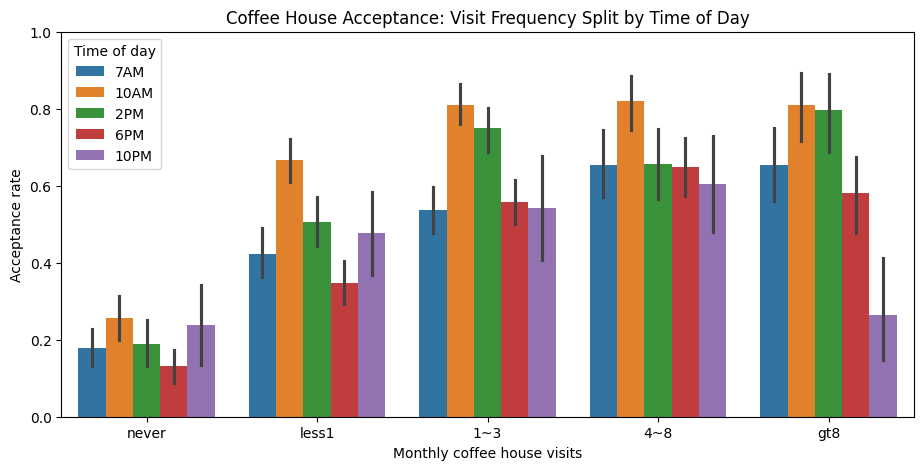

In [17]:
# Combine the two strongest levers: visit frequency split BY time of day.
# hue adds a second category, so Seaborn draws grouped bars of acceptance rate.
plt.figure(figsize=(11, 5))
sns.barplot(data=coffee, x='CoffeeHouse', y='Y', hue='time',
            order=visit_order, hue_order=time_order)
plt.title('Coffee House Acceptance: Visit Frequency Split by Time of Day')
plt.xlabel('Monthly coffee house visits')
plt.ylabel('Acceptance rate')
plt.ylim(0, 1)
plt.legend(title='Time of day')
plt.show()

The two strongest factors reinforce each other. A regular coffee drinker who gets a morning coupon is about as likely to accept as anyone in the dataset, while someone who never goes for coffee stays unlikely to bite whenever you reach them.

---
# Findings and recommendations

**The question.** What separates drivers who accept a coupon from those who turn it down, both overall and for the bar and coffee house offers specifically?

**What the data shows**

Overall acceptance runs about 57%, but that headline hides a lot of variation by coupon type and situation. The most useful predictor turned out to be whether someone already frequents the kind of place the coupon is for. Frequent bar-goers accept bar coupons 77% of the time against 37% for everyone else, and regular coffee drinkers accept coffee coupons around 65-69% versus just 19% for people who never go.

Bar coupons are the weakest of the bunch at 41% overall. They really only land with an existing bar crowd (over 25, no kid in the car), where acceptance climbs toward 71%. Coffee house coupons start near a coin flip at 50%, and the context does the tipping from there: mornings, having a friend or partner along, and a longer one-day expiration all push acceptance up.

**What I'd do with this**

- Lead with habit. Send bar and coffee coupons to people who already go to those places, and stop spending bar offers on people who never do.
- Push coffee coupons in the morning, and lean toward social contexts where you can.
- Default coffee coupons to a one-day window instead of two hours.
- Rethink bar coupons for a general audience. Either sweeten the offer or hold them for the frequent-visitor segment.

**Where I'd take it next**

- Run the same breakdown on the coupon types I didn't dig into here (cheap restaurants, carry-out, pricier restaurants).
- Fit a simple model like logistic regression to see how much each factor adds once the others are accounted for.
- Treat the expiration result as a hypothesis worth testing directly with an experiment.